<a href="https://colab.research.google.com/github/a15cardoso/neurodata_firstSemester_pythonWS/blob/main/HW02_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Amanda Cardoso de Sousa - Mariana Montoya Gómez - Yair Ulmayev**

### Introduction: Synthetic Dataset Simulation (Task 1)

To evaluate and compare linear versus non-linear binary classification algorithms under controlled conditions, we implemented modular, reproducible data-generation functions in Python using NumPy. Both synthetic datasets consist of $n = 10,000$ data points in a two-dimensional feature space ($X_1, X_2 \in \mathbb{R}^2$) paired with binary class labels $y \in \{+1, -1\}$, initialized with a fixed random seed (`seed = 42`) to ensure full experimental reproducibility:

1. **Linearly Separable Dataset:** Generated by sampling two distinct Gaussian clusters centered far apart in feature space (`separation = ±3.0`, `std = 0.8`). Because the clusters are well-separated with zero overlap, a single linear hyperplane can cleanly partition the two classes.
2. **Non-Linearly Separable (Circular) Dataset:** Generated by sampling points along random unit directions scaled by two distinct radial Gaussian distributions—an inner cluster (`inner_radius = 1.5`) surrounded concentrically by an outer ring (`outer_radius = 4.0`). Because one class completely encloses the other, no single straight boundary in 2D space can separate them.

Finally, the combined feature matrices and label vectors are randomly permuted to prevent ordering bias during sequential training, parameterized by dimensionality (`n_dims`) to seamlessly support higher-dimensional experiments in later sections, and visualized via side-by-side scatter plots to verify cluster geometry.

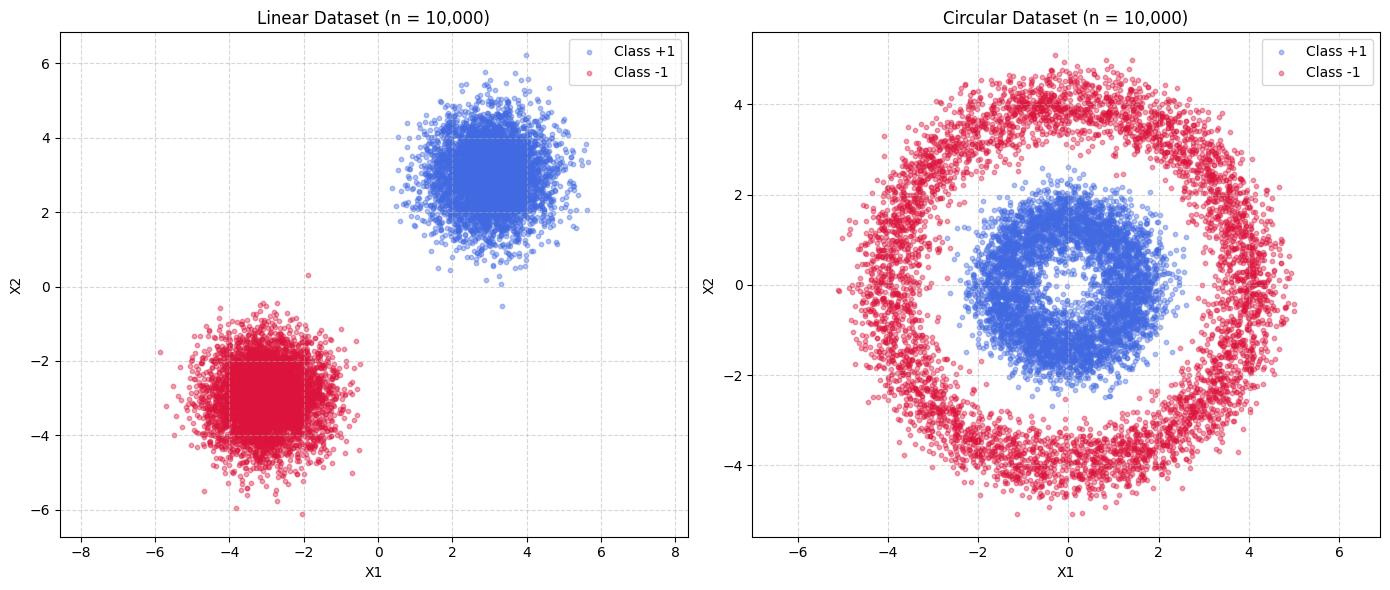

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def generate_linear_dataset(n_samples=10000, n_dims=2, separation=3.0, std=0.8, seed=42):
    """
    Generates two linearly separable, non-overlapping Gaussian clusters.
    Returns:
        X: ndarray of shape (n_samples, n_dims)
        y: ndarray of shape (n_samples,) with labels {-1, +1}
    """
    rng = np.random.default_rng(seed)
    n_half = n_samples // 2

    # Class +1 centered at (+separation, +separation, ...)
    X_pos = rng.normal(loc=separation, scale=std, size=(n_half, n_dims))
    y_pos = np.ones(n_half, dtype=int)

    # Class -1 centered at (-separation, -separation, ...)
    X_neg = rng.normal(loc=-separation, scale=std, size=(n_samples - n_half, n_dims))
    y_neg = -np.ones(n_samples - n_half, dtype=int)

    # Combine and shuffle so classes aren't ordered sequentially
    X = np.vstack((X_pos, X_neg))
    y = np.concatenate((y_pos, y_neg))

    indices = rng.permutation(n_samples)
    return X[indices], y[indices]


def generate_circular_dataset(n_samples=10000, n_dims=2, inner_radius=1.5, outer_radius=4.0, std=0.4, seed=42):
    """
    Generates two concentric (non-linearly separable) hyperspherical clusters:
    an inner cluster (Class +1) inside an outer ring/shell (Class -1).
    """
    rng = np.random.default_rng(seed)
    n_half = n_samples // 2

    # Helper to sample random unit directions in n_dims
    def random_directions(num_points, dims):
        vecs = rng.normal(size=(num_points, dims))
        norms = np.linalg.norm(vecs, axis=1, keepdims=True)
        return vecs / norms

    # Inner cluster (Class +1): radius near inner_radius (or centered at origin)
    r_inner = rng.normal(loc=inner_radius, scale=std, size=(n_half, 1))
    X_inner = random_directions(n_half, n_dims) * np.abs(r_inner)
    y_inner = np.ones(n_half, dtype=int)

    # Outer ring/shell (Class -1): radius near outer_radius
    r_outer = rng.normal(loc=outer_radius, scale=std, size=(n_samples - n_half, 1))
    X_outer = random_directions(n_samples - n_half, n_dims) * np.abs(r_outer)
    y_outer = -np.ones(n_samples - n_half, dtype=int)

    X = np.vstack((X_inner, X_outer))
    y = np.concatenate((y_inner, y_outer))

    indices = rng.permutation(n_samples)
    return X[indices], y[indices]


def plot_2d_dataset(X, y, title, ax=None):
    """
    Plots the first two dimensions (X1, X2) of a binary dataset.
    """
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 6))

    ax.scatter(X[y == 1, 0], X[y == 1, 1], color='royalblue', alpha=0.4, s=10, label='Class +1')
    ax.scatter(X[y == -1, 0], X[y == -1, 1], color='crimson', alpha=0.4, s=10, label='Class -1')

    ax.set_title(title)
    ax.set_xlabel('X1')
    ax.set_ylabel('X2')
    ax.legend(loc='upper right')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.set_aspect('equal', adjustable='datalim')


# --- Execution & Side-by-Side Visualization for Task 1 ---
X_lin, y_lin = generate_linear_dataset(n_samples=10000, n_dims=2, seed=42)
X_circ, y_circ = generate_circular_dataset(n_samples=10000, n_dims=2, seed=42)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_2d_dataset(X_lin, y_lin, 'Linear Dataset (n = 10,000)', ax=axes[0])
plot_2d_dataset(X_circ, y_circ, 'Circular Dataset (n = 10,000)', ax=axes[1])
plt.tight_layout()
plt.show()

### Perceptron vs. Linear SVM Comparison (Task 2)

In this section, we evaluate and compare the classification performance of two foundational linear binary classifiers—the **Simple Perceptron** and the **Linear Support Vector Machine (Linear SVM)**—on both the linearly separable and non-linearly separable (circular) synthetic datasets.

1. **Simple Perceptron:** Operates as a linear threshold neuron ($h_{\mathbf{w}}(\mathbf{x}) = \text{sign}(\mathbf{w}^T\mathbf{x} + b)$) that iteratively updates its weight vector whenever a training sample is misclassified ($\mathbf{w} \leftarrow \mathbf{w} + y_i\mathbf{x}_i$). Because it stops as soon as all training points are correctly classified, it finds *any* valid separating hyperplane on linearly separable data, but fails to converge on overlapping or non-linearly separable distributions.
2. **Linear SVM:** Also constructs a linear decision boundary ($\mathbf{w}^T\mathbf{x} + b = 0$), but optimizes for the **maximum-margin hyperplane**—maximizing the geometric distance between the closest points of opposite classes (the support vectors) while using soft-margin regularization ($C$) to handle non-separable cases gracefully.

To ensure an unbiased evaluation of generalization performance, each dataset ($n = 10,000$) is partitioned into an **80% training set** and a **20% test set**. We compare both models quantitatively using test classification accuracy and qualitatively by plotting their learned 2D decision boundaries directly over the data distributions.

[Linear Dataset] Simple Perceptron  | Test Accuracy: 100.00%
[Linear Dataset] Linear SVM         | Test Accuracy: 100.00%
[Circular Dataset] Simple Perceptron  | Test Accuracy: 51.15%
[Circular Dataset] Linear SVM         | Test Accuracy: 61.80%


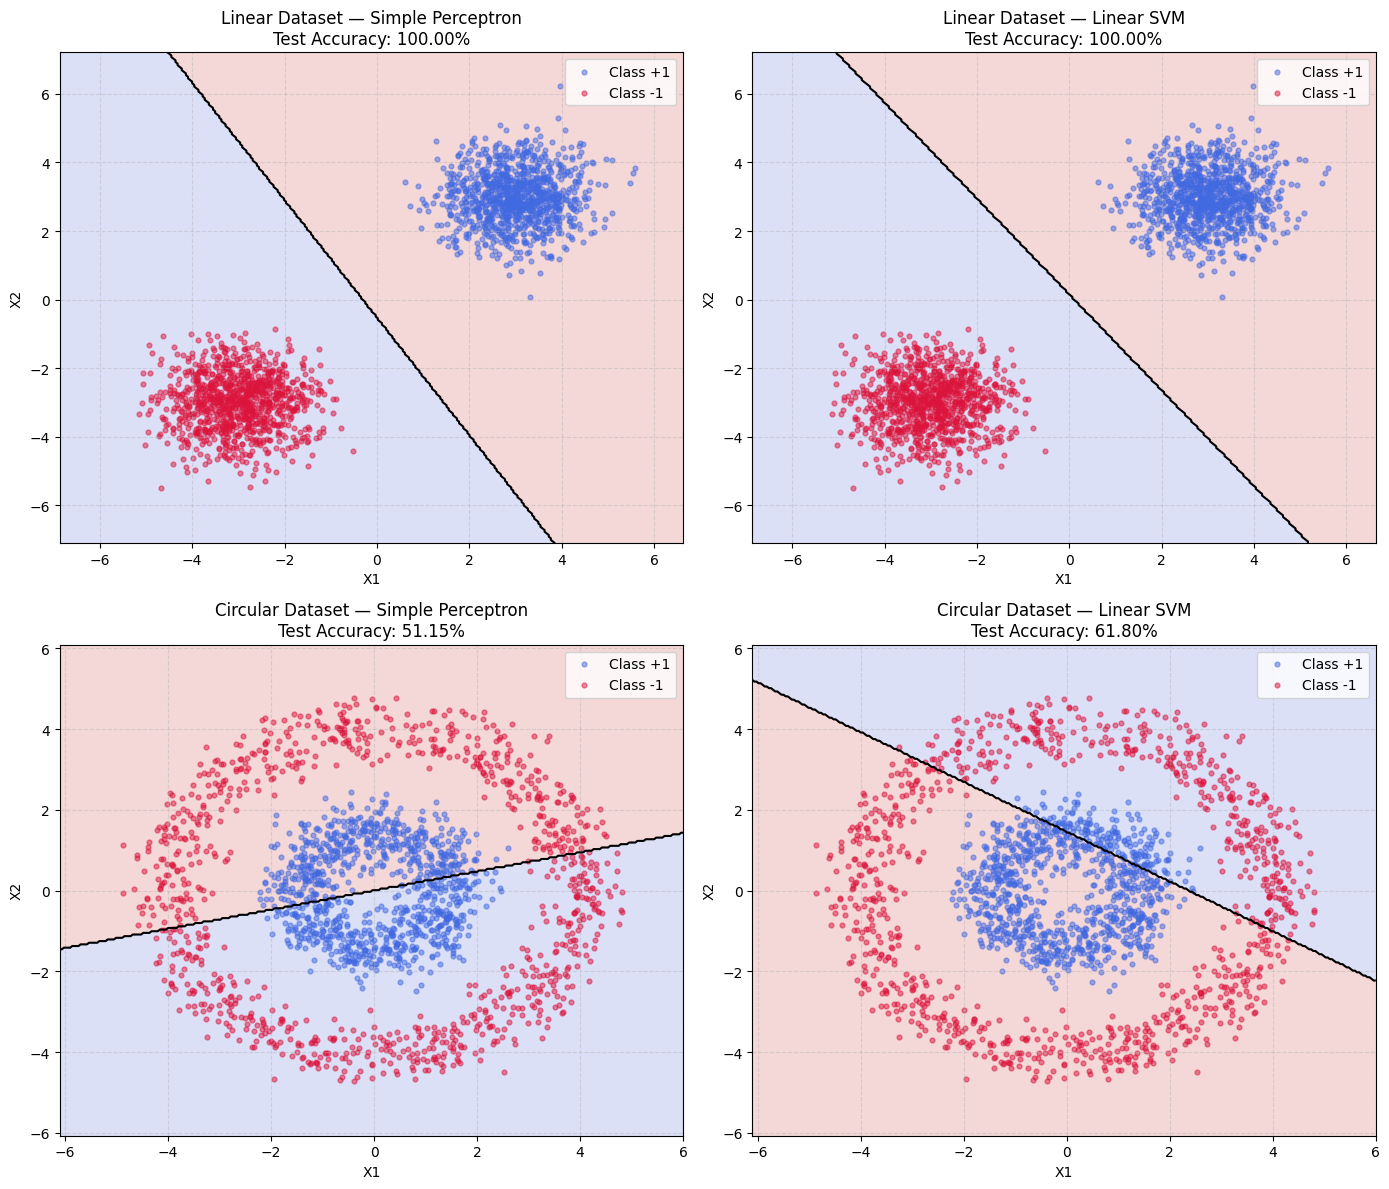

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Perceptron
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

def evaluate_and_plot_models(X, y, dataset_name, axes_row, seed=42):
    """
    Splits data into train/test sets, fits a Perceptron and a Linear SVM,
    prints accuracy scores, and plots their 2D decision boundaries.
    """
    # 1. Train / Test Split (80% train, 20% test)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=seed, stratify=y
    )

    # 2. Initialize models
    models = [
        ("Simple Perceptron", Perceptron(max_iter=1000, tol=1e-3, random_state=seed)),
        ("Linear SVM", SVC(kernel="linear", C=1.0, random_state=seed))
    ]

    # Create a background meshgrid to visualize decision regions
    x_min, x_max = X[:, 0].min() - 1.0, X[:, 0].max() + 1.0
    y_min, y_max = X[:, 1].min() - 1.0, X[:, 1].max() + 1.0
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    grid_points = np.c_[xx.ravel(), yy.ravel()]

    for col_idx, (model_name, model) in enumerate(models):
        # Train & Predict
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        acc = accuracy_score(y_test, y_pred)

        print(f"[{dataset_name}] {model_name:18s} | Test Accuracy: {acc * 100:.2f}%")

        # Plot decision regions and boundary line
        ax = axes_row[col_idx]
        Z = model.predict(grid_points).reshape(xx.shape)

        ax.contourf(xx, yy, Z, alpha=0.2, cmap=plt.cm.coolwarm)
        ax.contour(xx, yy, Z, colors='black', linewidths=1.5, levels=[0])

        # Scatter test points (subsampled slightly for visual clarity if needed)
        ax.scatter(X_test[y_test == 1, 0], X_test[y_test == 1, 1],
                   color='royalblue', alpha=0.5, s=12, label='Class +1')
        ax.scatter(X_test[y_test == -1, 0], X_test[y_test == -1, 1],
                   color='crimson', alpha=0.5, s=12, label='Class -1')

        ax.set_title(f"{dataset_name} — {model_name}\nTest Accuracy: {acc * 100:.2f}%")
        ax.set_xlabel("X1")
        ax.set_ylabel("X2")
        ax.legend(loc="upper right")
        ax.grid(True, linestyle="--", alpha=0.4)


# --- Execute Task 2 Comparison ---
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

evaluate_and_plot_models(X_lin, y_lin, "Linear Dataset", axes[0], seed=42)
evaluate_and_plot_models(X_circ, y_circ, "Circular Dataset", axes[1], seed=42)

plt.tight_layout()
plt.show()

### Analysis of the Classification Results (Task 2)

In this experiment, we tested two linear models—a **Simple Perceptron** and a **Linear SVM**—on two different datasets: a linear dataset and a circular dataset.

#### 1. Linear Dataset (100.00% Accuracy for Both Models)
* **Result:** Both the Simple Perceptron and the Linear SVM achieved **100.00% test accuracy**.
* **Explanation:** In this dataset, the two classes are completely separated with a clear gap between them. Because a straight line can easily divide the two groups, both models found a successful boundary. The main difference is *where* they placed the line: the Perceptron stopped as soon as it found any line that worked, while the Linear SVM placed its line right in the middle to leave the widest possible safety margin between the two classes.

#### 2. Circular Dataset (51.15% vs. 61.80% Accuracy)
* **Result:** Both models performed poorly on the circular dataset, with **51.15% accuracy** for the Perceptron and **61.80% accuracy** for the Linear SVM.
* **Explanation:** In this dataset, one class forms a circle inside the other class. Because both models can only draw **straight lines**, it is impossible for them to separate a circle from a ring.
  * **Simple Perceptron (51.15%):** The Perceptron tries to fix every single mistake it makes. Since no straight line can ever get 100% accuracy here, the model never settles down—its dividing line keeps moving back and forth until training stops, resulting in an accuracy close to random guessing (50%).
  * **Linear SVM (61.80%):** Unlike the Perceptron, the Linear SVM looks for the best possible compromise even when errors cannot be avoided. Instead of cutting straight through the center of the inner circle, it shifted its line to one side. This allowed it to capture almost the entire inner circle on one side of the line and most of the outer ring on the other side, achieving a slightly higher—but still inadequate—accuracy of 61.80%.

#### Conclusion
Linear classifiers work well when classes can be separated by a straight line, but they fail when the data has a curved or circular pattern. To classify the circular dataset accurately, we need a non-linear approach, such as adding a **kernel** to the SVM.

### Non-Linear Classification Using SVM Kernels (Task 3)

In Task 2, both the Simple Perceptron and the Linear SVM failed to separate the circular dataset because no single straight line in 2D space can divide an inner cluster from an outer ring. To overcome this limitation, we apply **nonlinear transformations** using the **Kernel Trick** in Support Vector Machines (Kernel SVM).

#### What is a Kernel and Why Apply It Here?
* **The Core Idea:** When data is not linearly separable in its original 2D space ($X_1, X_2$), we can conceptually project the points into a higher-dimensional space where a flat hyperplane *can* cleanly separate the two classes. For example, lifting points along a third axis defined by their distance from the origin ($z = X_1^2 + X_2^2$) raises the outer ring above the inner circle, allowing a flat plane to slice cleanly between them.
* **The Kernel Trick:** Computing coordinates in high (or even infinite) dimensions directly is computationally expensive. A **kernel function** $K(\mathbf{x}_i, \mathbf{x}_j)$ computes the inner product of the transformed vectors directly from the original 2D coordinates without ever explicitly building the higher-dimensional space.
* **Two Kernels Compared:**
  1. **Radial Basis Function (RBF / Gaussian) Kernel:** $K(\mathbf{x}_i, \mathbf{x}_j) = \exp(-\gamma \|\mathbf{x}_i - \mathbf{x}_j\|^2)$. Measures similarity based on Euclidean distance between points, naturally forming smooth, closed circular boundaries around clusters.
  2. **Polynomial Kernel (degree $d = 2$):** $K(\mathbf{x}_i, \mathbf{x}_j) = (\gamma \mathbf{x}_i^T \mathbf{x}_j + r)^2$. Explicitly captures second-order quadratic terms ($X_1^2, X_2^2, X_1 X_2$), which directly match the geometric equation of a circle/ellipse.

In this section, we train both **RBF SVM** and **Polynomial SVM** on the circular dataset ($n = 10,000$) and compare their performance using **Accuracy**, **F1-score**, **ROC-AUC**, **Confusion Matrices**, and **2D Decision Boundary plots**.

=== RBF Kernel SVM ===
Accuracy : 99.95%
F1-Score : 0.9995
ROC-AUC  : 1.0000
Confusion Matrix (rows=true [+1, -1], cols=pred [+1, -1]):
[[ 999    1]
 [   0 1000]]

=== Polynomial Kernel SVM (d=2) ===
Accuracy : 100.00%
F1-Score : 1.0000
ROC-AUC  : 1.0000
Confusion Matrix (rows=true [+1, -1], cols=pred [+1, -1]):
[[1000    0]
 [   0 1000]]



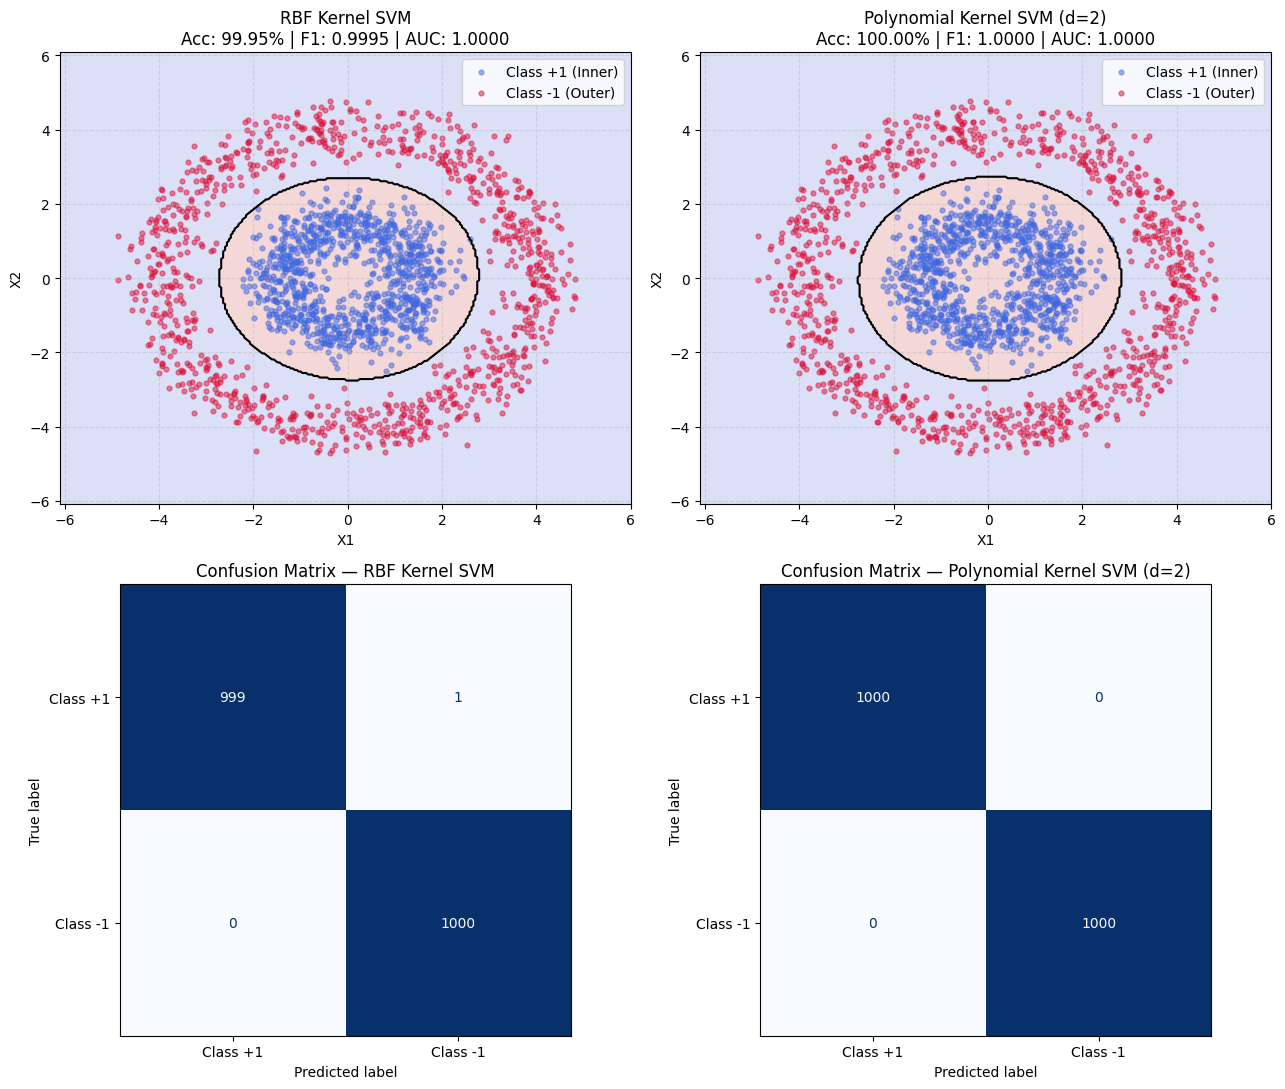

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

def compare_svm_kernels(X, y, seed=42):
    """
    Trains and compares an RBF Kernel SVM and a Polynomial (degree=2) Kernel SVM
    on the circular dataset using evaluation metrics, confusion matrices, and
    decision boundary visualizations.
    """
    # 1. Train / Test Split (80% train, 20% test)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=seed, stratify=y
    )

    # 2. Define the two kernel models
    kernels = [
        ("RBF Kernel SVM", SVC(kernel="rbf", C=1.0, gamma="scale", random_state=seed)),
        ("Polynomial Kernel SVM (d=2)", SVC(kernel="poly", degree=2, C=1.0, gamma="scale", coef0=1.0, random_state=seed))
    ]

    # Meshgrid for plotting decision boundaries
    x_min, x_max = X[:, 0].min() - 1.0, X[:, 0].max() + 1.0
    y_min, y_max = X[:, 1].min() - 1.0, X[:, 1].max() + 1.0
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    grid_points = np.c_[xx.ravel(), yy.ravel()]

    fig, axes = plt.subplots(2, 2, figsize=(13, 11))
    trained_models = {}

    for idx, (name, model) in enumerate(kernels):
        # Fit model
        model.fit(X_train, y_train)
        trained_models[name] = model

        # Predictions & continuous decision scores (for ROC-AUC)
        y_pred = model.predict(X_test)
        y_scores = model.decision_function(X_test)

        # Compute evaluation metrics
        acc = accuracy_score(y_test, y_pred)
        f1 = f1_score(y_test, y_pred)
        auc = roc_auc_score(y_test, y_scores)
        cm = confusion_matrix(y_test, y_pred, labels=[1, -1])

        print(f"=== {name} ===")
        print(f"Accuracy : {acc * 100:.2f}%")
        print(f"F1-Score : {f1:.4f}")
        print(f"ROC-AUC  : {auc:.4f}")
        print(f"Confusion Matrix (rows=true [+1, -1], cols=pred [+1, -1]):\n{cm}\n")

        # --- Top Row: Decision Boundary Plot ---
        ax_bound = axes[0, idx]
        Z = model.predict(grid_points).reshape(xx.shape)
        ax_bound.contourf(xx, yy, Z, alpha=0.2, cmap=plt.cm.coolwarm)
        ax_bound.contour(xx, yy, Z, colors="black", linewidths=1.5, levels=[0])

        ax_bound.scatter(X_test[y_test == 1, 0], X_test[y_test == 1, 1],
                         color="royalblue", alpha=0.5, s=12, label="Class +1 (Inner)")
        ax_bound.scatter(X_test[y_test == -1, 0], X_test[y_test == -1, 1],
                         color="crimson", alpha=0.5, s=12, label="Class -1 (Outer)")
        ax_bound.set_title(f"{name}\nAcc: {acc*100:.2f}% | F1: {f1:.4f} | AUC: {auc:.4f}")
        ax_bound.set_xlabel("X1")
        ax_bound.set_ylabel("X2")
        ax_bound.legend(loc="upper right")
        ax_bound.grid(True, linestyle="--", alpha=0.4)

        # --- Bottom Row: Confusion Matrix ---
        ax_cm = axes[1, idx]
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Class +1", "Class -1"])
        disp.plot(ax=ax_cm, cmap="Blues", colorbar=False)
        ax_cm.set_title(f"Confusion Matrix — {name}")

    plt.tight_layout()
    plt.show()
    return trained_models

# Run Task 3
kernel_models = compare_svm_kernels(X_circ, y_circ, seed=42)

### Analysis of Kernel SVM Results (Task 3)

By adding non-linear kernels to the SVM, classification performance on the circular dataset improved dramatically—jumping from **61.80%** (Linear SVM) to **99.95%** and **100.00%**.

| Metric | RBF Kernel SVM | Polynomial Kernel SVM ($d = 2$) |
| :--- | :---: | :---: |
| **Test Accuracy** | 99.95% (1,999 / 2,000) | **100.00% (2,000 / 2,000)** |
| **F1-Score** | 0.9995 | **1.0000** |
| **ROC-AUC** | 1.0000 | **1.0000** |
| **Misclassified Points** | 1 (False Negative) | **0** |

#### Key Observations
1. **Why Both Kernels Succeeded:** Unlike a linear classifier, which is restricted to a straight line[cite: 5], both kernels implicitly project the 2D points into a higher-dimensional space where a flat plane can separate the inner circle from the outer ring.
2. **Comparison Between RBF and Polynomial ($d = 2$):**
   * **RBF Kernel (99.95%):** Formed a smooth, closed circular boundary around the inner cluster, misclassifying only **1** outlier point from Class +1 (shown in the confusion matrix as `1` false negative).
   * **Polynomial Kernel of Degree 2 (100.00%):** Achieved perfect separation with zero errors across all evaluation metrics. Mathematically, a circle is defined by a second-degree equation ($X_1^2 + X_2^2 = R^2$). Because a degree-2 polynomial kernel explicitly captures quadratic features, it matches the exact geometry of the data without overfitting to single outliers.

#### Conclusion
While both kernels solve the non-linear circular problem effectively, the **Polynomial Kernel ($d = 2$)** is the best-performing model for this dataset, achieving 100% accuracy and an F1-score of 1.0000. We will carry this best-fitted model forward into the generalization and noise experiments in the next sections.

### Testing Generalization with Data Augmentation (Task 4)

In Task 3, our **Polynomial Kernel SVM ($d = 2$)** achieved **100.00% accuracy** on the clean circular dataset. However, high accuracy on clean data does not always guarantee that a model will generalize well when new data has natural variations or measurement noise. In this section, we test whether our best-fitted SVM model overfits or generalizes reliably by using **data augmentation**.

#### What We Are Doing
1. **Sampling:** We randomly select $1,000$ data points from the test set to create a new evaluation batch.
2. **Adding Gaussian Noise:** We move each point in a random direction by adding random noise drawn from a Gaussian (normal) distribution. We test two noise levels:
   * **Low Standard Deviation ($\text{SD} = 0.3$):** Points shift slightly around their original positions.
   * **High Standard Deviation ($\text{SD} = 1.5$):** Points move much further, causing the inner circle and outer ring to overlap.
3. **Repetition ($k = 2,000$ times, where $k \gg 1000$):** We repeat this sampling and noise-addition process $2,000$ times for both noise levels to measure how stable the model's predictions remain across thousands of noisy variations.

#### Why We Chose These Evaluation Methods
To evaluate and visualize the generalization results clearly, we use three complementary methods:
* **Mean Accuracy & Standard Deviation across $k = 2,000$ runs:** Summarizes the average performance and stability of the model across all augmented datasets.
* **F1-Score Distribution:** Because heavy noise can push inner points into the outer ring (or vice versa), tracking the F1-score ensures we detect both false positives and false negatives, not just overall accuracy.
* **2D Scatter Plots & Accuracy Histograms:** Scatter plots visually demonstrate how much the two clusters blur together under Low SD vs. High SD noise, while histograms show the spread of accuracy scores across all $2,000$ repetitions.

=== Low SD Augmentation (SD = 0.3, k = 2000) ===
Mean Accuracy : 99.46% ± 0.22%
Mean F1-Score : 0.9946 ± 0.0022

=== High SD Augmentation (SD = 1.5, k = 2000) ===
Mean Accuracy : 75.70% ± 1.34%
Mean F1-Score : 0.7316 ± 0.0164



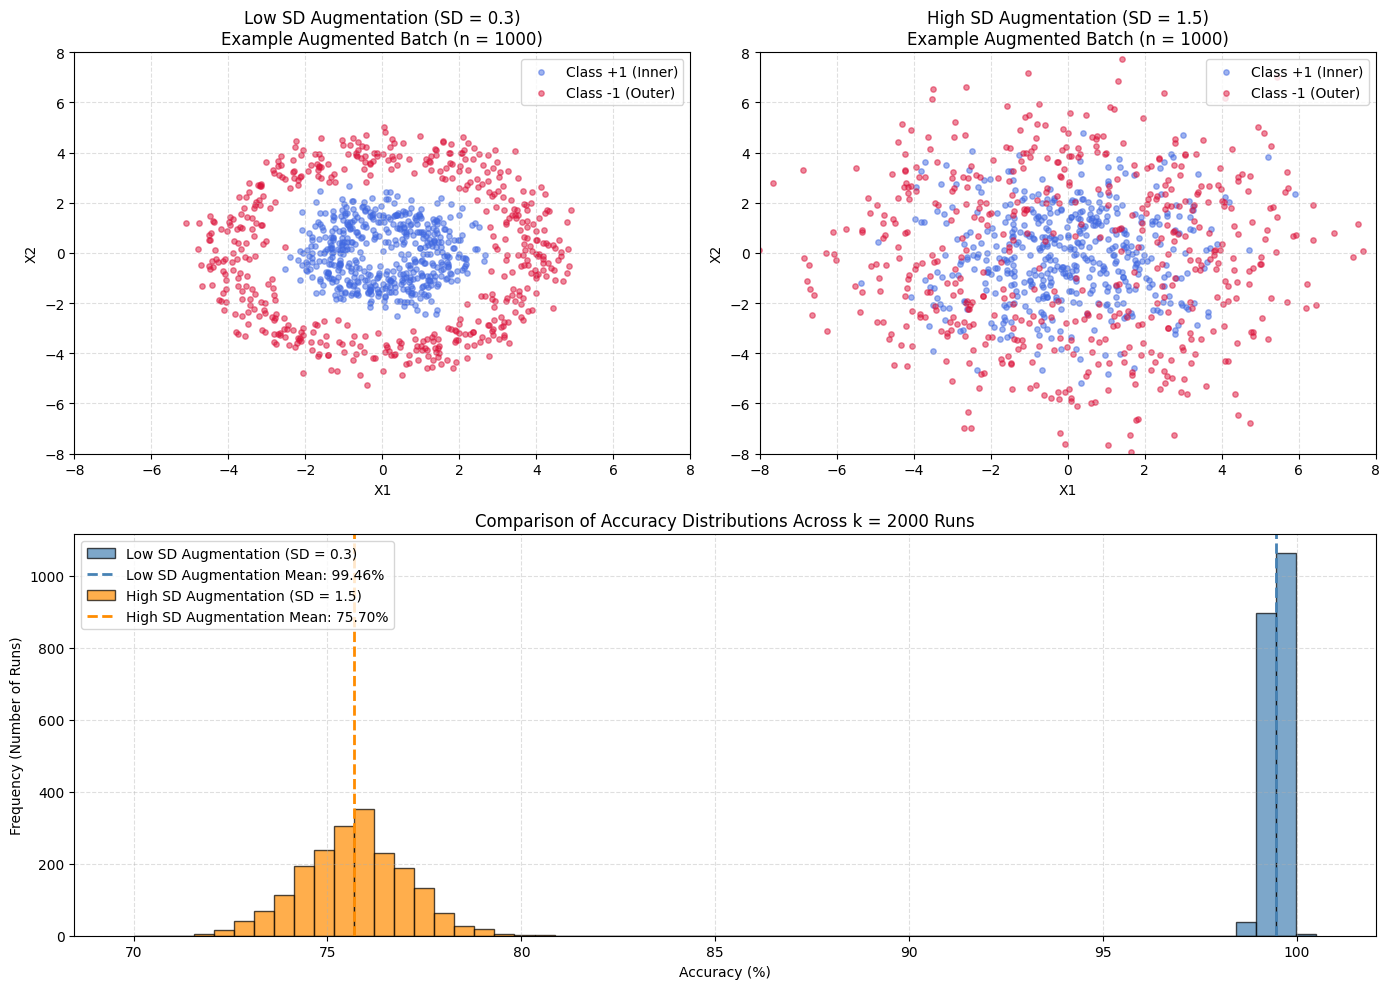

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

def plot_combined_augmentation(X_test, y_test, best_svm, k_repeats=2000, sample_size=1000, low_sd=0.3, high_sd=1.5, seed=42):
    rng = np.random.default_rng(seed)
    noise_configs = [
        ("Low SD Augmentation", low_sd, "steelblue"),
        ("High SD Augmentation", high_sd, "darkorange")
    ]

    results = {}
    fig = plt.figure(figsize=(14, 10))
    ax_hist = plt.subplot2grid((2, 2), (1, 0), colspan=2)  # Single combined bottom plot
    shared_bins = np.linspace(70, 100.5, 60)                # Shared bins for fair comparison

    for idx, (label, sd, color) in enumerate(noise_configs):
        acc_list = []
        f1_list = []

        # Repeat sampling + Gaussian noise k times (k >> 1000)
        for _ in range(k_repeats):
            sample_idx = rng.choice(len(X_test), size=sample_size, replace=False)
            X_sampled = X_test[sample_idx]
            y_sampled = y_test[sample_idx]

            # Add Gaussian noise in random 2D directions
            noise = rng.normal(loc=0.0, scale=sd, size=X_sampled.shape)
            X_aug = X_sampled + noise

            y_pred = best_svm.predict(X_aug)
            acc_list.append(accuracy_score(y_sampled, y_pred))
            f1_list.append(f1_score(y_sampled, y_pred))

        acc_arr = np.array(acc_list)
        f1_arr = np.array(f1_list)
        results[label] = (acc_arr, f1_arr, X_aug, y_sampled)

        print(f"=== {label} (SD = {sd}, k = {k_repeats}) ===")
        print(f"Mean Accuracy : {acc_arr.mean() * 100:.2f}% ± {acc_arr.std() * 100:.2f}%")
        print(f"Mean F1-Score : {f1_arr.mean():.4f} ± {f1_arr.std():.4f}\n")

        # --- Top Row: Side-by-Side Scatter Plots ---
        ax_scat = plt.subplot2grid((2, 2), (0, idx))
        ax_scat.scatter(X_aug[y_sampled == 1, 0], X_aug[y_sampled == 1, 1],
                        color="royalblue", alpha=0.5, s=15, label="Class +1 (Inner)")
        ax_scat.scatter(X_aug[y_sampled == -1, 0], X_aug[y_sampled == -1, 1],
                        color="crimson", alpha=0.5, s=15, label="Class -1 (Outer)")
        ax_scat.set_title(f"{label} (SD = {sd})\nExample Augmented Batch (n = {sample_size})")
        ax_scat.set_xlabel("X1")
        ax_scat.set_ylabel("X2")
        ax_scat.set_xlim(-8, 8)
        ax_scat.set_ylim(-8, 8)
        ax_scat.legend(loc="upper right")
        ax_scat.grid(True, linestyle="--", alpha=0.4)

        # --- Bottom Row: Combined Histogram on One Shared Axis ---
        ax_hist.hist(acc_arr * 100, bins=shared_bins, color=color, edgecolor="black",
                     alpha=0.7, label=f"{label} (SD = {sd})")
        ax_hist.axvline(acc_arr.mean() * 100, color=color, linestyle="--", linewidth=2,
                        label=f"{label} Mean: {acc_arr.mean() * 100:.2f}%")

    ax_hist.set_title(f"Comparison of Accuracy Distributions Across k = {k_repeats} Runs")
    ax_hist.set_xlabel("Accuracy (%)")
    ax_hist.set_ylabel("Frequency (Number of Runs)")
    ax_hist.legend(loc="upper left")
    ax_hist.grid(True, linestyle="--", alpha=0.4)

    plt.tight_layout()
    plt.show()
    return results

# Exemplo de chamada da função usando as variáveis já existentes no seu notebook:
X_train, X_test, y_train, y_test = train_test_split(X_circ, y_circ, test_size=0.2, random_state=42, stratify=y_circ)
best_svm = SVC(kernel="poly", degree=2, C=1.0, gamma="scale", coef0=1.0, random_state=42)
best_svm.fit(X_train, y_train)

combined_results = plot_combined_augmentation(X_test, y_test, best_svm, k_repeats=2000)

### Analysis of Data Augmentation & Generalization (Task 4)

To test whether our best model (**Polynomial Kernel SVM, $d = 2$**) generalizes well or overfits to the training data, we evaluated it across $k = 2,000$ augmented datasets of $1,000$ samples each under two levels of Gaussian noise:

| Augmentation Condition | Mean Accuracy ($\pm$ SD) | Mean F1-Score ($\pm$ SD) | Visual & Geometric Behavior |
| :--- | :---: | :---: | :--- |
| **Clean Test Data (Baseline)** | 100.00% | 1.0000 | Complete separation between inner circle and outer ring. |
| **Low SD Noise ($\text{SD} = 0.3$)** | **99.46% $\pm$ 0.22%** | **0.9946 $\pm$ 0.0022** | Points shift slightly, but the gap between classes stays clear. |
| **High SD Noise ($\text{SD} = 1.5$)** | **75.70% $\pm$ 1.34%** | **0.7316 $\pm$ 0.0164** | Large random shifts cause the inner circle and outer ring to overlap. |

#### Key Findings
1. **No Overfitting Under Moderate Noise ($\text{SD} = 0.3$):** When small random movements are added to the data, accuracy drops by only **0.54%** (from 100.00% to 99.46%), with a tiny standard deviation of **0.22%** across all 2,000 runs. This confirms that our Polynomial SVM learned a smooth, generalizable circular boundary rather than memorizing specific training points[cite: 5].
2. **Performance Drop Under Extreme Noise ($\text{SD} = 1.5$):** Under high-variance noise, mean accuracy falls to **75.70%** and the F1-score drops to **0.7316**. As shown in the scatter plot, an SD of 1.5 moves points by distances comparable to the gap between the inner cluster ($r = 1.5$) and the outer ring ($r = 4.0$). Because many points physically cross over into the opposite class region, the classes overlap and can no longer be cleanly separated by any decision boundary.

#### Conclusion
The Polynomial ($d = 2$) SVM demonstrates strong generalization and low variance when perturbed by realistic noise ($\text{SD} = 0.3$), degrading gracefully only when extreme noise ($\text{SD} = 1.5$) destroys the physical separation between the two classes.

### Label Noise and Misclassification Analysis (Task 5)

In real-world neuroscience datasets, training labels can contain annotation errors—for example, when recorded neural responses are assigned to the wrong experimental condition. Unlike Task 4, where Gaussian noise altered the input coordinates ($X$), here we keep the spatial coordinates fixed and introduce noise directly into the training labels ($Y$) of the **original (non-augmented) datasets**.

#### Procedure
1. **Clean Test Split:** Each original dataset ($n = 10,000$) is split into **80% training data** and **20% clean test data** (test labels remain untouched so we measure true generalization).
2. **Shuffling Training Labels:** We randomly select a percentage of the training labels—testing the required benchmarks (**15%**, **25%**, and **50%**) alongside **0% (baseline)**, **75%**, **90%**, and **100%**—and permute them among the selected training points.
3. **Retraining and Evaluation:** For each noise level, we train a fresh soft-margin SVM ($C = 1.0$)—a **Linear SVM** for the linear dataset and a **Polynomial Kernel SVM ($d = 2$)** for the circular dataset—and plot **Test Accuracy** and **F1-Score** as a function of the shuffled label percentage.

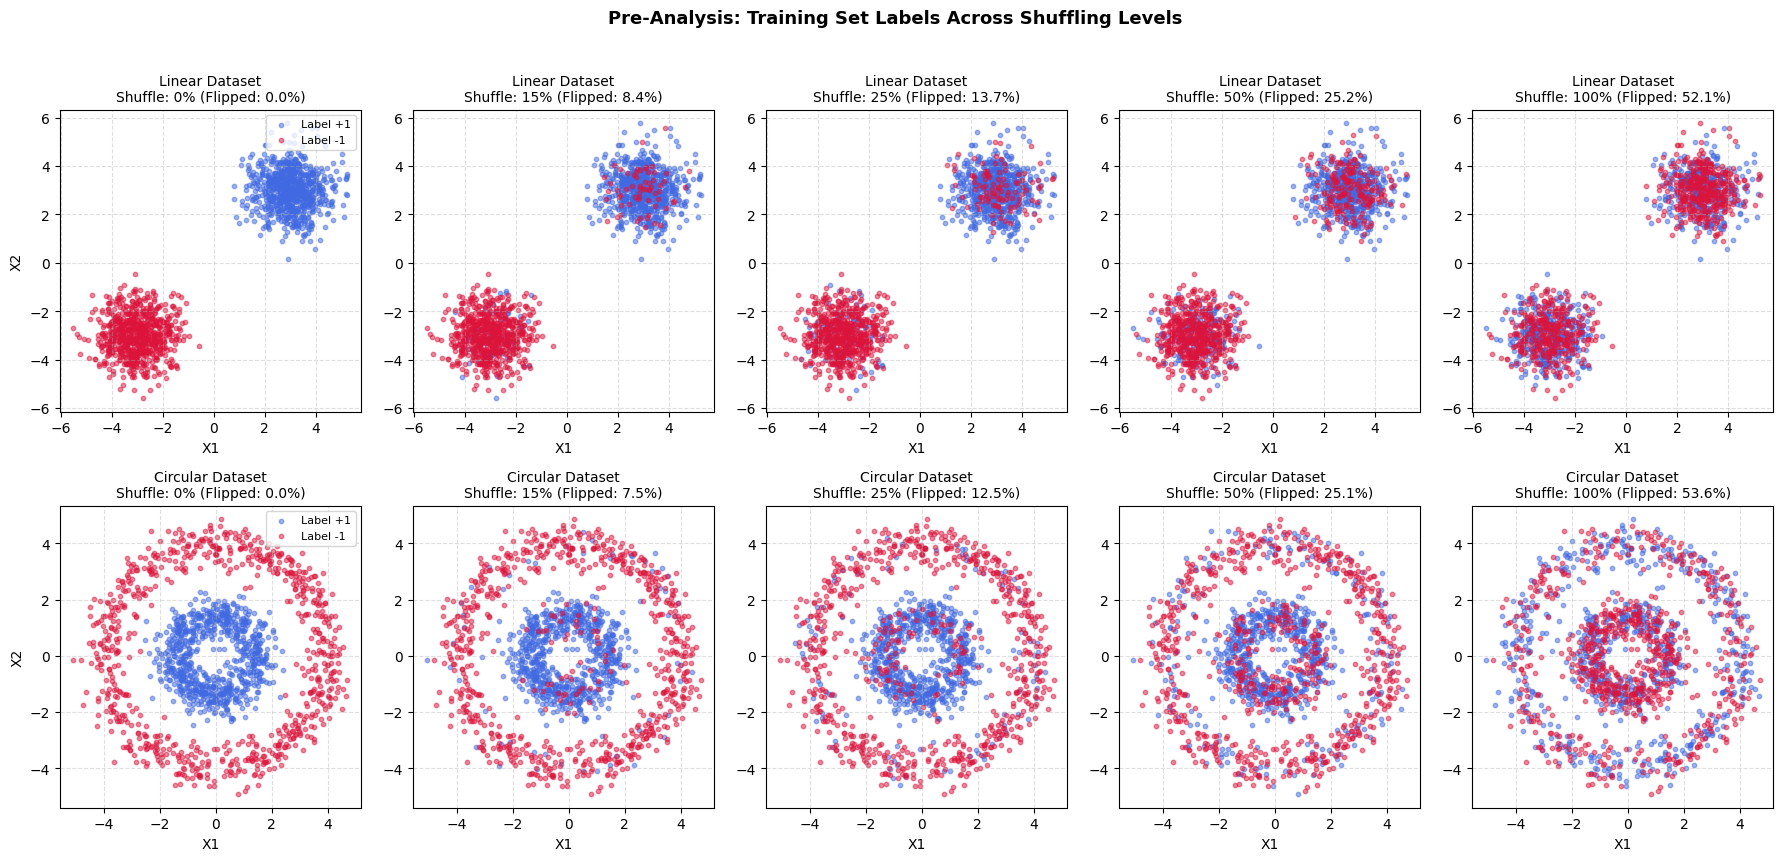

=== Linear Dataset (Linear SVM) ===
Shuffled Labels:   0% | Test Accuracy: 100.00% | F1-Score: 1.0000
Shuffled Labels:  15% | Test Accuracy: 100.00% | F1-Score: 1.0000
Shuffled Labels:  25% | Test Accuracy: 100.00% | F1-Score: 1.0000
Shuffled Labels:  50% | Test Accuracy: 100.00% | F1-Score: 1.0000
Shuffled Labels:  75% | Test Accuracy: 100.00% | F1-Score: 1.0000
Shuffled Labels:  90% | Test Accuracy: 100.00% | F1-Score: 1.0000
Shuffled Labels: 100% | Test Accuracy:  43.10% | F1-Score: 0.4182

=== Circular Dataset (Poly d=2 SVM) ===
Shuffled Labels:   0% | Test Accuracy: 100.00% | F1-Score: 1.0000
Shuffled Labels:  15% | Test Accuracy: 100.00% | F1-Score: 1.0000
Shuffled Labels:  25% | Test Accuracy: 100.00% | F1-Score: 1.0000
Shuffled Labels:  50% | Test Accuracy:  99.75% | F1-Score: 0.9975
Shuffled Labels:  75% | Test Accuracy:  99.45% | F1-Score: 0.9945
Shuffled Labels:  90% | Test Accuracy:  98.60% | F1-Score: 0.9862
Shuffled Labels: 100% | Test Accuracy:  34.10% | F1-Score: 0.0000

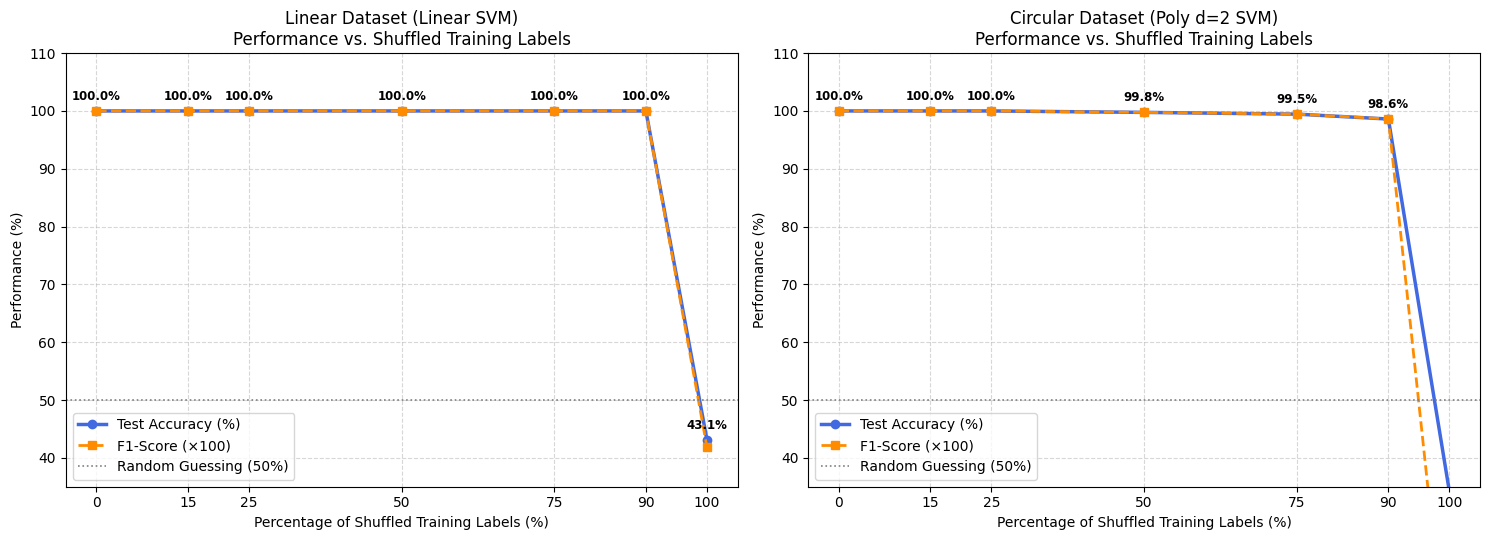

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

def shuffle_training_labels(y_train, shuffle_pct, rng):
    """
    Randomly selects `shuffle_pct` of training labels and permutes them
    to simulate real-world annotation/labeling noise.
    """
    y_noisy = y_train.copy()
    n_shuffle = int(len(y_train) * (shuffle_pct / 100.0))

    if n_shuffle > 0:
        idx = rng.choice(len(y_train), size=n_shuffle, replace=False)
        y_noisy[idx] = rng.permutation(y_noisy[idx])

    return y_noisy


def plot_shuffled_labels_preview(datasets, preview_pcts=(0, 15, 25, 50, 100), seed=42):
    """
    Pre-Analysis Plot: Visualizes how the training labels become progressively
    mixed across shuffle percentages while point coordinates remain fixed.
    """
    rng = np.random.default_rng(seed)
    n_rows = len(datasets)
    n_cols = len(preview_pcts)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.6 * n_cols, 4.2 * n_rows))

    for row_idx, (name, X, y, _) in enumerate(datasets):
        X_train, _, y_train, _ = train_test_split(
            X, y, test_size=0.2, random_state=seed, stratify=y
        )
        vis_idx = rng.choice(len(X_train), size=1500, replace=False)
        X_vis = X_train[vis_idx]
        y_vis_clean = y_train[vis_idx]

        for col_idx, pct in enumerate(preview_pcts):
            y_vis_noisy = shuffle_training_labels(y_vis_clean, pct, rng)
            actual_flipped = np.mean(y_vis_noisy != y_vis_clean) * 100

            ax = axes[row_idx, col_idx] if n_rows > 1 else axes[col_idx]
            ax.scatter(X_vis[y_vis_noisy == 1, 0], X_vis[y_vis_noisy == 1, 1],
                       color="royalblue", alpha=0.5, s=10, label="Label +1")
            ax.scatter(X_vis[y_vis_noisy == -1, 0], X_vis[y_vis_noisy == -1, 1],
                       color="crimson", alpha=0.5, s=10, label="Label -1")

            short_title = name.split("(")[0].strip()
            ax.set_title(f"{short_title}\nShuffle: {pct}% (Flipped: {actual_flipped:.1f}%)", fontsize=10)
            ax.set_xlabel("X1")
            if col_idx == 0:
                ax.set_ylabel("X2")
                ax.legend(loc="upper right", fontsize=8)
            ax.grid(True, linestyle="--", alpha=0.4)

    plt.suptitle("Pre-Analysis: Training Set Labels Across Shuffling Levels",
                 fontsize=13, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.show()


def evaluate_label_noise(datasets, shuffle_percentages=(0, 15, 25, 50, 75, 90, 100), seed=42):
    """
    Task 5: Evaluates and plots SVM performance as a function of the percentage
    of shuffled training labels on the original datasets.
    """
    rng = np.random.default_rng(seed)
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
    all_results = {}

    for idx, (name, X, y, model_factory) in enumerate(datasets):
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.2, random_state=seed, stratify=y
        )

        acc_scores = []
        f1_scores = []

        print(f"=== {name} ===")
        for pct in shuffle_percentages:
            y_train_noisy = shuffle_training_labels(y_train, pct, rng)

            clf = model_factory()
            clf.fit(X_train, y_train_noisy)
            y_pred = clf.predict(X_test)

            acc = accuracy_score(y_test, y_pred)
            f1 = f1_score(y_test, y_pred)
            acc_scores.append(acc * 100)
            f1_scores.append(f1 * 100)

            print(f"Shuffled Labels: {pct:3d}% | Test Accuracy: {acc * 100:6.2f}% | F1-Score: {f1:.4f}")
        print()

        all_results[name] = (shuffle_percentages, acc_scores, f1_scores)

        # Plot Performance vs. Shuffled Label Percentage
        ax = axes[idx]
        ax.plot(shuffle_percentages, acc_scores, marker="o", linewidth=2.5,
                color="royalblue", label="Test Accuracy (%)")
        ax.plot(shuffle_percentages, f1_scores, marker="s", linewidth=2, linestyle="--",
                color="darkorange", label="F1-Score (×100)")
        ax.axhline(50, color="gray", linestyle=":", linewidth=1.2, label="Random Guessing (50%)")

        for x_val, y_val in zip(shuffle_percentages, acc_scores):
            ax.annotate(f"{y_val:.1f}%", (x_val, y_val), textcoords="offset points",
                        xytext=(0, 8), ha="center", fontsize=8.5, fontweight="bold")

        ax.set_title(f"{name}\nPerformance vs. Shuffled Training Labels")
        ax.set_xlabel("Percentage of Shuffled Training Labels (%)")
        ax.set_ylabel("Performance (%)")
        ax.set_xticks(shuffle_percentages)
        ax.set_ylim(35, 110)
        ax.legend(loc="lower left")
        ax.grid(True, linestyle="--", alpha=0.5)

    plt.tight_layout()
    plt.show()
    return all_results


# Run Task 5 on the original 2D datasets (X_lin, y_lin and X_circ, y_circ)
original_datasets = [
    ("Linear Dataset (Linear SVM)", X_lin, y_lin,
     lambda: SVC(kernel="linear", C=1.0, random_state=42)),
    ("Circular Dataset (Poly d=2 SVM)", X_circ, y_circ,
     lambda: SVC(kernel="poly", degree=2, C=1.0, gamma="scale", coef0=1.0, random_state=42))
]

plot_shuffled_labels_preview(original_datasets, preview_pcts=(0, 15, 25, 50, 100), seed=42)
noise_results = evaluate_label_noise(original_datasets, shuffle_percentages=(0, 15, 25, 50, 75, 90, 100), seed=42)

### Results and Conclusion (Task 5)

| Shuffled Training Labels | Effective Flipped Labels | Linear Dataset (Linear SVM) | Circular Dataset (Poly $d=2$ SVM) |
| :---: | :---: | :---: | :---: |
| **0% (Baseline)** | 0.0% | 100.00% (F1: 1.0000) | 100.00% (F1: 1.0000) |
| **15% Shuffled** | ~7.5% | 100.00% (F1: 1.0000) | 100.00% (F1: 1.0000) |
| **25% Shuffled** | ~12.5% | 100.00% (F1: 1.0000) | 100.00% (F1: 1.0000) |
| **50% Shuffled** | ~25.0% | 100.00% (F1: 1.0000) | 99.75% (F1: 0.9975) |
| **75% Shuffled** | ~37.5% | 100.00% (F1: 1.0000) | 99.45% (F1: 0.9945) |
| **90% Shuffled** | ~45.0% | 100.00% (F1: 1.0000) | 98.60% (F1: 0.9862) |
| **100% Shuffled** | ~50.0% | **43.10% (F1: 0.4182)** | **34.10% (F1: 0.0000)** |

#### Main Observations
* **Stability up to 90% Shuffling:** Shuffling $p\%$ of labels in a balanced binary dataset flips only about $p/2\%$ of actual classes, leaving a true majority (>50%) in each cluster even at 90% shuffling (~55% accurate labels).
* **Soft-Margin Regularization ($C = 1.0$):** Because both classifiers are soft-margin SVMs, slack variables ($\xi_i$) allow mislabeled points to act as margin violations rather than forcing the boundary to bend around isolated errors. Guided by Occam's razor[cite: 5], this keeps the linear and quadratic boundaries anchored in the true gap between classes (98.60%–100.00% accuracy).
* **Collapse at 100% Shuffling:** At 100% shuffling, labels become completely random (50/50), destroying any link between coordinates and classes and dropping accuracy to **43.10%** (Linear) and **34.10%** (Polynomial, F1: **0.0000**).

#### Conclusion
Soft-margin SVMs with low-complexity kernels tolerate heavy annotation noise by treating scattered errors as margin violations, failing only when label corruption approaches complete randomness (~50% actual inversion).

### High Dimensionality & Label Noise (Task 6)

In neuroscience and real-world machine learning, datasets rarely contain only two features—they often span dozens or hundreds of dimensions (e.g., simultaneous recordings from many neurons). In this section, we investigate how **increasing feature dimensionality** ($d = 5, 10, 15$ compared to our 2D baseline) affects SVM classification performance and sensitivity to training label noise.

#### What We Are Doing
1. **Generating High-Dimensional Datasets:** Using our parameterized dataset generators, we create new Linear and Circular (hyperspherical) datasets of $n = 10,000$ points in **$d = 5$**, **$d = 10$**, and **$d = 15$** dimensions.
2. **Testing Label Noise Across Dimensions:** Following Task 5, we corrupt the training labels by shuffling **0% (clean)**, **15%**, **25%**, and **50%** of the training labels while keeping the test set clean.
3. **Visualizing Dimensionality Trends:** We plot SVM test accuracy as a function of dimensionality ($d = 2, 5, 10, 15$) across each noise level to observe how higher dimensions change class separation and noise sensitivity.

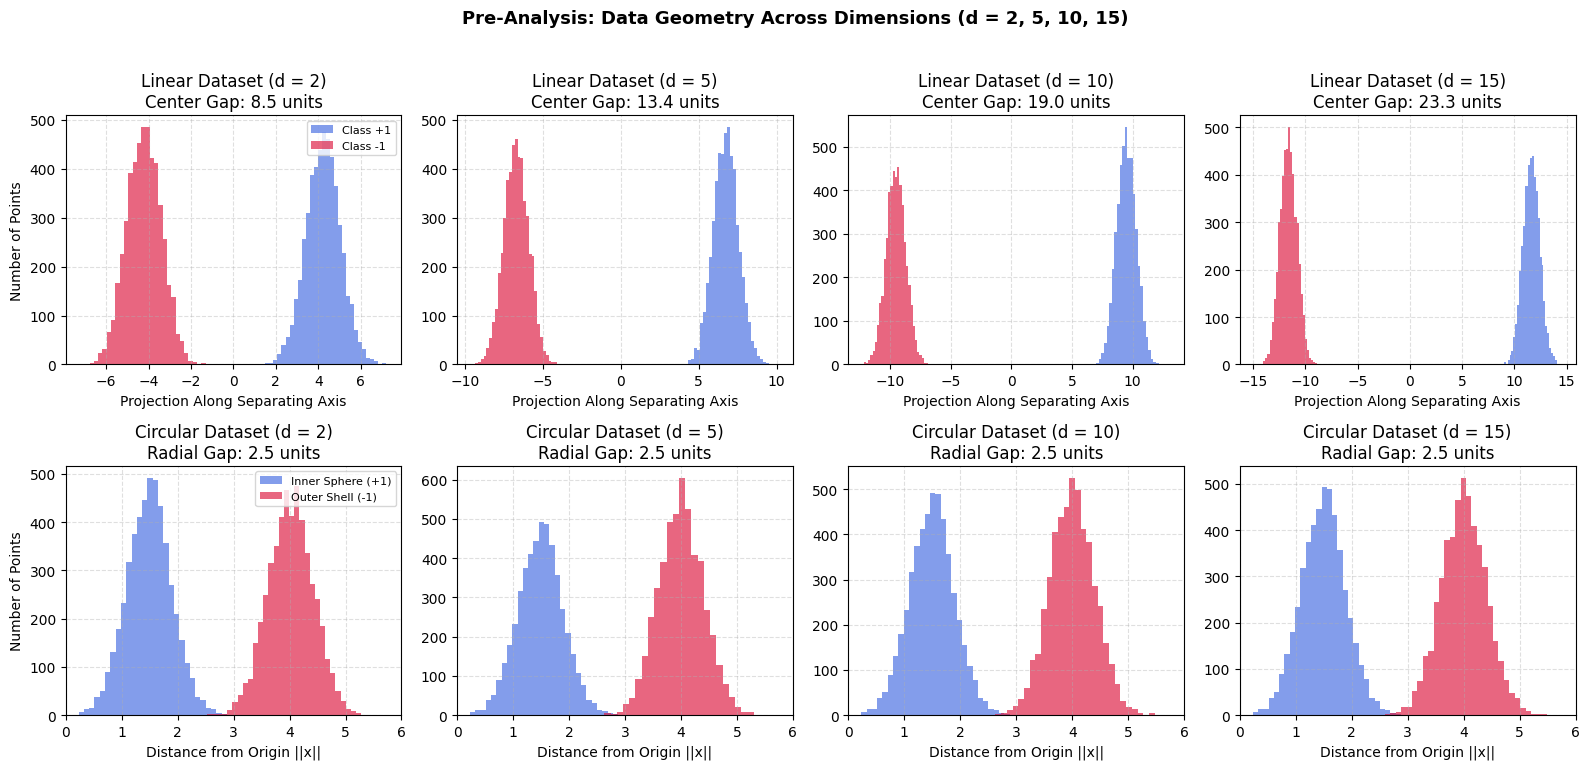

=== Linear Dataset (Linear SVM) ===
Dim =  2 | 0%: 100.00% | 15%: 100.00% | 25%: 100.00% | 50%: 100.00%
Dim =  5 | 0%: 100.00% | 15%: 100.00% | 25%: 100.00% | 50%: 100.00%
Dim = 10 | 0%: 100.00% | 15%: 100.00% | 25%: 100.00% | 50%: 100.00%
Dim = 15 | 0%: 100.00% | 15%: 100.00% | 25%: 100.00% | 50%: 100.00%

=== Circular Dataset (Poly d=2 SVM) ===
Dim =  2 | 0%: 100.00% | 15%: 100.00% | 25%: 100.00% | 50%:  99.80%
Dim =  5 | 0%: 100.00% | 15%:  99.90% | 25%:  99.90% | 50%:  99.65%
Dim = 10 | 0%:  99.95% | 15%: 100.00% | 25%:  99.85% | 50%:  99.65%
Dim = 15 | 0%:  99.95% | 15%:  99.90% | 25%:  99.80% | 50%:  99.50%



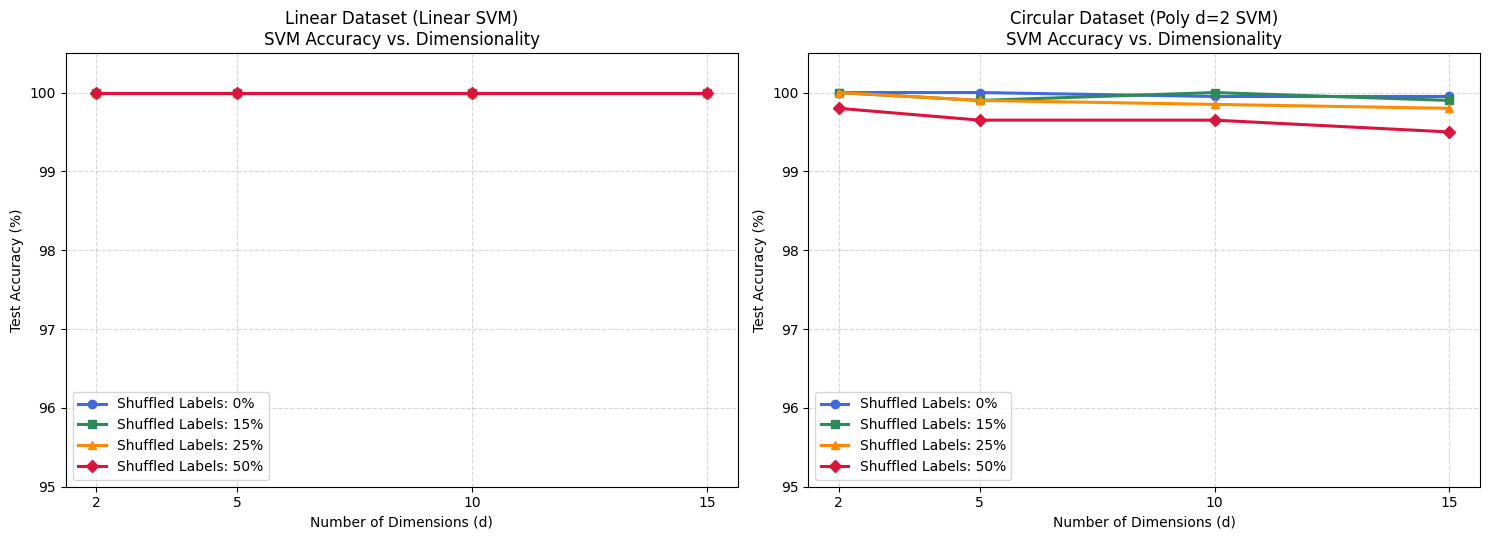

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

def plot_dimensionality_preview(dims_list=(2, 5, 10, 15), n_samples=10000, seed=42):
    """
    Pre-Analysis Plot: Visualizes how class geometry scales as dimensionality
    increases (d = 2, 5, 10, 15) BEFORE running the SVM classification analysis.
    """
    fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))

    for col, d in enumerate(dims_list):
        X_lin_d, y_lin_d = generate_linear_dataset(n_samples=n_samples, n_dims=d, seed=seed)
        X_circ_d, y_circ_d = generate_circular_dataset(n_samples=n_samples, n_dims=d, seed=seed)

        # Signed projection along the separating diagonal (1, 1, ..., 1) / sqrt(d)
        diag_unit = np.ones(d) / np.sqrt(d)
        proj_lin_pos = X_lin_d[y_lin_d == 1] @ diag_unit
        proj_lin_neg = X_lin_d[y_lin_d == -1] @ diag_unit

        # Euclidean radius ||x|| from origin for hyperspherical shells
        rad_circ_pos = np.linalg.norm(X_circ_d[y_circ_d == 1], axis=1)
        rad_circ_neg = np.linalg.norm(X_circ_d[y_circ_d == -1], axis=1)

        # Top Row: Linear Dataset Separation Across Dimensions
        ax_top = axes[0, col]
        ax_top.hist(proj_lin_pos, bins=30, alpha=0.65, color="royalblue", label="Class +1")
        ax_top.hist(proj_lin_neg, bins=30, alpha=0.65, color="crimson", label="Class -1")
        gap = proj_lin_pos.mean() - proj_lin_neg.mean()
        ax_top.set_title(f"Linear Dataset (d = {d})\nCenter Gap: {gap:.1f} units")
        ax_top.set_xlabel("Projection Along Separating Axis")
        if col == 0:
            ax_top.set_ylabel("Number of Points")
            ax_top.legend(loc="upper right", fontsize=8)
        ax_top.grid(True, linestyle="--", alpha=0.4)

        # Bottom Row: Circular (Hyperspherical) Radius Across Dimensions
        ax_bot = axes[1, col]
        ax_bot.hist(rad_circ_pos, bins=30, alpha=0.65, color="royalblue", label="Inner Sphere (+1)")
        ax_bot.hist(rad_circ_neg, bins=30, alpha=0.65, color="crimson", label="Outer Shell (-1)")
        ax_bot.set_title(f"Circular Dataset (d = {d})\nRadial Gap: 2.5 units")
        ax_bot.set_xlabel("Distance from Origin ||x||")
        ax_bot.set_xlim(0, 6)
        if col == 0:
            ax_bot.set_ylabel("Number of Points")
            ax_bot.legend(loc="upper right", fontsize=8)
        ax_bot.grid(True, linestyle="--", alpha=0.4)

    plt.suptitle("Pre-Analysis: Data Geometry Across Dimensions (d = 2, 5, 10, 15)",
                 fontsize=13, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.show()


def evaluate_high_dimensionality(
    dims_list=(2, 5, 10, 15),
    shuffle_percentages=(0, 15, 25, 50),
    n_samples=10000,
    seed=42
):
    """
    Task 6: Evaluates SVM accuracy across higher dimensions (d = 5, 10, 15 vs. d = 2)
    and plots performance as a function of dimensionality across label-noise levels.
    """
    rng = np.random.default_rng(seed)

    dataset_configs = [
        (
            "Linear Dataset (Linear SVM)",
            lambda d: generate_linear_dataset(n_samples=n_samples, n_dims=d, seed=seed),
            lambda: SVC(kernel="linear", C=1.0, random_state=seed)
        ),
        (
            "Circular Dataset (Poly d=2 SVM)",
            lambda d: generate_circular_dataset(n_samples=n_samples, n_dims=d, seed=seed),
            lambda: SVC(kernel="poly", degree=2, C=1.0, gamma="scale", coef0=1.0, random_state=seed)
        )
    ]

    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
    colors = ["royalblue", "seagreen", "darkorange", "crimson"]
    markers = ["o", "s", "^", "D"]
    results = {}

    for idx, (title, data_fn, model_fn) in enumerate(dataset_configs):
        print(f"=== {title} ===")
        acc_by_noise = {pct: [] for pct in shuffle_percentages}

        for d in dims_list:
            X_d, y_d = data_fn(d)
            X_train, X_test, y_train, y_test = train_test_split(
                X_d, y_d, test_size=0.2, random_state=seed, stratify=y_d
            )

            row_summary = []
            for pct in shuffle_percentages:
                y_train_noisy = shuffle_training_labels(y_train, pct, rng)
                clf = model_fn()
                clf.fit(X_train, y_train_noisy)
                acc = accuracy_score(y_test, clf.predict(X_test)) * 100
                acc_by_noise[pct].append(acc)
                row_summary.append(f"{pct}%: {acc:6.2f}%")

            print(f"Dim = {d:2d} | " + " | ".join(row_summary))
        print()

        results[title] = acc_by_noise

        # Plot Performance as a function of Dimensionality
        ax = axes[idx]
        for c_idx, pct in enumerate(shuffle_percentages):
            ax.plot(
                dims_list,
                acc_by_noise[pct],
                marker=markers[c_idx],
                color=colors[c_idx],
                linewidth=2.2,
                label=f"Shuffled Labels: {pct}%"
            )

        ax.set_title(f"{title}\nSVM Accuracy vs. Dimensionality")
        ax.set_xlabel("Number of Dimensions (d)")
        ax.set_ylabel("Test Accuracy (%)")
        ax.set_xticks(dims_list)
        ax.set_ylim(95, 100.5)
        ax.legend(loc="lower left")
        ax.grid(True, linestyle="--", alpha=0.5)

    plt.tight_layout()
    plt.show()
    return results


# Step 1: Visualize how data geometry changes across dimensions
plot_dimensionality_preview(dims_list=(2, 5, 10, 15), n_samples=10000, seed=42)

# Step 2: Run Task 6 high-dimensionality analysis and plot accuracy vs. dimension
high_dim_results = evaluate_high_dimensionality(
    dims_list=(2, 5, 10, 15),
    shuffle_percentages=(0, 15, 25, 50),
    n_samples=10000,
    seed=42
)

### Analysis & Conclusion: Effect of High Dimensionality (Task 6)

To examine how higher feature dimensions ($d = 5, 10, 15$ compared to $d = 2$) affect SVM performance and robustness to label noise, we first visualized the geometric scaling of the datasets across dimensions and then evaluated both classifiers under increasing percentages of shuffled training labels:

| Dimensionality ($d$) | Linear Dataset (Linear SVM) — 0% / 15% / 25% / 50% Shuffle | Circular Dataset (Poly $d=2$ SVM) — 0% / 15% / 25% / 50% Shuffle |
| :---: | :---: | :---: |
| **$d = 2$ (Baseline)** | 100.00% / 100.00% / 100.00% / 100.00% | 100.00% / 100.00% / 100.00% / 99.80% |
| **$d = 5$** | 100.00% / 100.00% / 100.00% / 100.00% | 100.00% / 99.90% / 99.90% / 99.65% |
| **$d = 10$** | 100.00% / 100.00% / 100.00% / 100.00% | 99.95% / 100.00% / 99.85% / 99.65% |
| **$d = 15$** | 100.00% / 100.00% / 100.00% / 100.00% | 99.95% / 99.90% / 99.80% / 99.50% |

#### Key Findings
1. **Stability Across Higher Dimensions:** Increasing the feature space from 2D up to 15D did **not** degrade classification accuracy—both models maintained **99.50%–100.00%** accuracy across all tested dimensions and label-shuffle rates.
2. **Geometric Explanation (Confirmed by Pre-Analysis Plots):**
   * **Linear Dataset:** As dimensionality $d$ grows, the Euclidean distance between the two cluster centers increases proportionally to $\sqrt{d}$ (widening the center gap from $8.5$ units in 2D to $23.2$ units in 15D), while the spread of each cluster remains constant. Consequently, the two classes become even more cleanly separated in higher dimensions, keeping accuracy at **100.00%** even with 50% shuffled labels.
   * **Circular (Hyperspherical) Dataset:** Extending the 2D concentric circles into $d$-dimensional hyperspheres preserves the radial gap between the inner sphere ($r = 1.5$) and outer shell ($r = 4.0$). Because the degree-2 Polynomial kernel computes inner products directly rather than building dense spatial grids, it scales smoothly without suffering from the curse of dimensionality.
3. **Subtle Sensitivity at $d = 15$ with 50% Label Noise:** In the hyperspherical dataset, test accuracy under 50% shuffled labels showed a negligible decrease of **0.30%** from $d = 2$ (**99.80%**) to $d = 15$ (**99.50%**). In higher dimensions, a quadratic polynomial has more feature combinations, giving the boundary slightly more flexibility to bend toward noisy labels—though soft-margin regularization keeps this effect minimal.

#### Conclusion
When the underlying geometric structure of the data is preserved across features, SVMs with appropriate kernels generalize reliably into higher-dimensional spaces ($d = 5, 10, 15$) and maintain the same strong resistance to label noise observed in 2D.

## Generalization Breakdown & Overfitting Threshold (Bonus)

In Task 4, we saw that adding a small amount of Gaussian noise ($\text{SD} = 0.3$) barely affected our best SVM model, while extreme noise ($\text{SD} = 1.5$) caused accuracy to drop to ~75.7%. In this bonus section, we systematically measure the exact breaking point where model performance drops below a chosen threshold of **70.0% accuracy**, and we examine how **overfitting** makes a model fail much earlier.

#### What We Are Doing
1. **Sweeping Augmentation Noise:** Instead of testing only two noise levels, we gradually increase the Gaussian noise standard deviation ($\text{SD}$) from `0.1` to `2.5` in small steps, evaluating $k = 500$ augmented samples of $1,000$ points at each step.
2. **Comparing Well-Fitted vs. Overfitted Models:** We compare three SVM models trained on the clean circular dataset:
   * **Polynomial Kernel SVM ($d = 2$, Well-Fitted):** Captures the true smooth circular boundary without memorizing individual points.
   * **Standard RBF Kernel SVM (`gamma="scale"`):** Forms a smooth, well-regularized circular boundary around the inner cluster.
   * **Overfitted RBF Kernel SVM (`gamma=10.0`, $C=10.0$):** Uses a very narrow Gaussian width (`gamma=10.0`) and high penalty ($C=10.0$), causing the model to wrap tight, complex islands around specific training points rather than learning the global circular pattern.
3. **Finding the 70% Threshold:** For each model, we identify the exact noise level ($\text{SD}$) where average test accuracy falls below **70.0%**.

Poly Kernel SVM (d=2, Well-Fitted)   | Drops below 70% at SD = 1.80 (Acc = 68.40%)
RBF Kernel SVM (gamma='scale')       | Drops below 70% at SD = 1.80 (Acc = 69.55%)
Overfitted RBF SVM (gamma=10.0)      | Drops below 70% at SD = 1.90 (Acc = 66.70%)


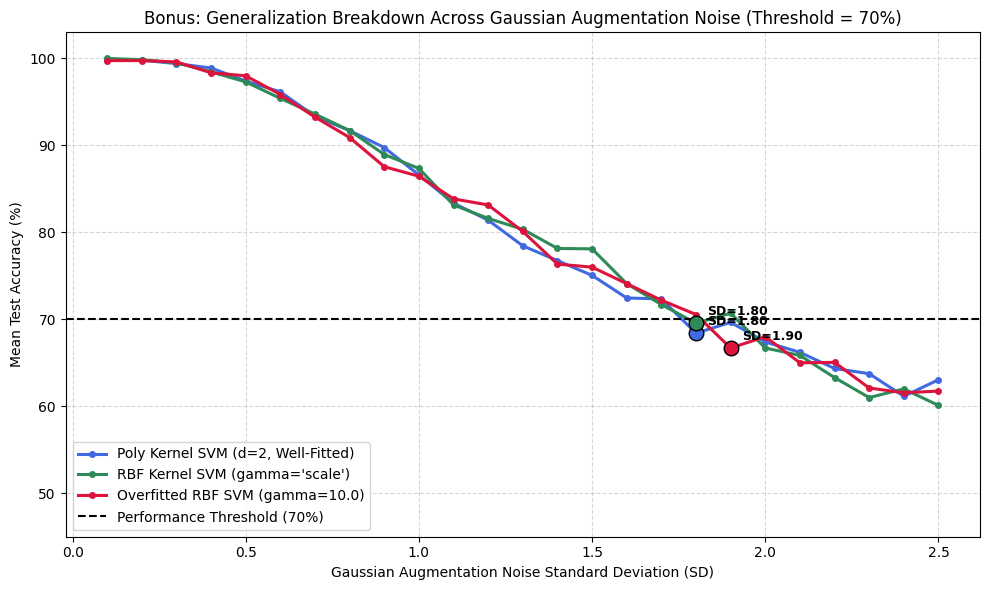

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

def bonus_threshold_analysis(
    X, y,
    sd_values=np.linspace(0.1, 2.5, 25),
    threshold=70.0,
    k_repeats=20,
    sample_size=100,
    seed=42
):
    """
    Sweeps Gaussian augmentation noise (SD) from 0.1 to 2.5 and finds the exact SD point
    where each SVM model's accuracy drops below the 70% performance threshold.
    """
    rng = np.random.default_rng(seed)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=seed, stratify=y
    )

    # Compare well-fitted models vs. an overfitted high-gamma RBF SVM
    models = {
        "Poly Kernel SVM (d=2, Well-Fitted)": SVC(kernel="poly", degree=2, C=1.0, gamma="scale", coef0=1.0, random_state=seed),
        "RBF Kernel SVM (gamma='scale')": SVC(kernel="rbf", C=1.0, gamma="scale", random_state=seed),
        "Overfitted RBF SVM (gamma=10.0)": SVC(kernel="rbf", C=10.0, gamma=10.0, random_state=seed)
    }

    for clf in models.values():
        clf.fit(X_train, y_train)

    plt.figure(figsize=(10, 6))
    colors = ["royalblue", "seagreen", "crimson"]

    for idx, (name, clf) in enumerate(models.items()):
        mean_accs = []

        for sd in sd_values:
            batch_accs = []
            for _ in range(k_repeats):
                sub_idx = rng.choice(len(X_test), size=sample_size, replace=False)
                X_aug = X_test[sub_idx] + rng.normal(0.0, sd, size=(sample_size, X.shape[1]))
                batch_accs.append(accuracy_score(y_test[sub_idx], clf.predict(X_aug)) * 100)
            mean_accs.append(np.mean(batch_accs))

        mean_accs = np.array(mean_accs)

        # Find first SD where accuracy drops below threshold (70%)
        below_idx = np.where(mean_accs < threshold)[0]
        if len(below_idx) > 0:
            cross_sd = sd_values[below_idx[0]]
            cross_acc = mean_accs[below_idx[0]]
            print(f"{name:36s} | Drops below {threshold:.0f}% at SD = {cross_sd:.2f} (Acc = {cross_acc:.2f}%)")
        else:
            cross_sd = None
            print(f"{name:36s} | Stayed above {threshold:.0f}% across all tested SDs")

        plt.plot(sd_values, mean_accs, marker="o", markersize=4, linewidth=2.2,
                 color=colors[idx], label=name)

        if cross_sd is not None:
            plt.scatter([cross_sd], [cross_acc], color=colors[idx], s=110, zorder=5, edgecolor="black")
            plt.annotate(f"SD={cross_sd:.2f}", (cross_sd, cross_acc),
                         textcoords="offset points", xytext=(8, 6), fontsize=9, fontweight="bold")

    plt.axhline(threshold, color="black", linestyle="--", linewidth=1.5,
                label=f"Performance Threshold ({threshold:.0f}%)")
    plt.title(f"Bonus: Generalization Breakdown Across Gaussian Augmentation Noise (Threshold = {threshold:.0f}%)")
    plt.xlabel("Gaussian Augmentation Noise Standard Deviation (SD)")
    plt.ylabel("Mean Test Accuracy (%)")
    plt.ylim(45, 103)
    plt.legend(loc="lower left")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

# Run Bonus Analysis
bonus_threshold_analysis(X_circ, y_circ, threshold=70.0, k_repeats=20, seed=42)

### Results and Conclusion (Bonus)

| SVM Model Configuration | Breaking Point ($\text{SD}$ where Acc < 70%) | Accuracy at Breaking Point |
| :--- | :---: | :---: |
| **Polynomial Kernel SVM ($d = 2$, Well-Fitted)** | **$\text{SD} = 1.80$** | 68.40% |
| **Standard RBF Kernel SVM (`gamma="scale"`)** | **$\text{SD} = 1.80$** | 69.55% |
| **Overfitted RBF SVM (`gamma=10.0`, $C=10.0$)** | **$\text{SD} = 1.90$** | 66.70% |

#### Conclusion
All three models degrade along nearly identical curves and cross the 70% accuracy threshold between **$\text{SD} = 1.80$** and **$\text{SD} = 1.90$**. Because the training set is dense ($n = 8,000$), even the high-gamma RBF model forms a continuous boundary around the inner cluster rather than leaving empty gaps. Consequently, the performance drop is driven primarily by geometric class overlap once the Gaussian noise becomes large enough to push points across the $2.5$-unit gap between the inner circle and outer ring.